<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/mse_logo.png" width="400" align="right"/>
<div style="text-align: left"> <b> Machine Learning FTP_MachLe </b> <br> HS 2026 <br> <a href="mailto:christoph.wuersch@ost.ch"> Christoph Würsch </a> </div>

In [1]:
# imports
from IPython.display import Image, display
from IPython.display import HTML
import os
import requests
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# allow plots to appear directly in the notebook
%matplotlib inline

# raw URL of this repository on GitHub (images, data)
filepath = "https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main"

# **Feature Engineering – Group 3: Data Cleaning and Integration**

**Authors:** *Name 1, Name 2, Name 3, ...*

### Instructor review (2026-10-08)

This notebook (Group 3 – Data Cleaning and Integration) was checked against the group-work assignment. Changes are marked directly in the notebook:

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> <span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> <span style="background-color:#d6e9f8;color:#0b4f7c;padding:2px 8px;border-radius:4px;font-weight:bold">[REVISED]</span> <span style="background-color:#e2e3e5;color:#383d41;padding:2px 8px;border-radius:4px;font-weight:bold">[REMOVED]</span>

Code changes are marked with a comment `# [ADDED]`, `# [CORRECTED]`, ... All changed cells also carry a cell tag `review-*`.

**Added**
- (i) explanation of `np.nan` (NaN != NaN, `isna`, dtype effects, sentinels, drop vs. impute) + demo cell
- (ii) one sentence + demo: trailing vs. centered window, look-ahead leakage, `shift(1)`
- (iii) complete section: equal-width / equal-frequency / domain bins, train-only edges with `KBinsDiscretizer`
- (iv) runnable example: per-sensor `ffill`/`bfill` with `limit`, train-only `SimpleImputer` with missing indicator
- (v) explanation of IQR, z-score and robust z-score (MAD); demo of z-score masking
- (vi) explanation of `how=`, keys, `validate=`, duplicates, `indicator=`; runnable merge demo
- Takeaways and References

**Corrected**
- (i) code used `rng` before it was defined (NameError on a fresh run)
- (ii) broken LaTeX formula of the moving average
- (iv) garbled median-imputation example; KDE is not an imputation method

**Revised for clarity**
- (iv) 'advanced filling techniques' moved to the end and shortened

**Removed (beyond course scope)**
- (iii) stray cell containing only `x` (no content)
- (iv) personal OpenStreetMap/KDE anecdote

**Open issue:** the authors cell still contains the template placeholders – author names must be added by the group.


<img src="https://raw.githubusercontent.com/ChristophWuersch/FeatureEngineering_HS2026/main/images/03_Data_Clearning.png" width="1200"/>

## Introduction

**What is it about?**
Raw data is rarely ready for modelling. It contains missing entries (`np.nan`), noisy measurements, outliers caused by sensor faults or typos, and it is often spread over several tables or files. *Data cleaning* covers detecting and handling missing values (dropping, forward/backward fill, median imputation), smoothing noisy signals (e.g. moving averages), discretizing continuous values into bins, and detecting and removing outliers. *Data integration* combines several sources into one consistent dataset, typically by merging or joining pandas DataFrames on common keys.

**Where is it used?**
In practically every real project: sensor and IoT time series with gaps and spikes, medical records with incomplete measurements, business data from different databases (customers, orders, products), and survey data with unanswered questions. Tools of choice are `pandas` (`isna`, `fillna`, `ffill`, `rolling`, `cut`, `merge`) and `sklearn.impute`.

**Why is it important for Machine Learning?**
"Garbage in, garbage out": most scikit-learn estimators cannot handle `NaN` at all, and outliers or noise can strongly distort means, variances and fitted models. Practitioners often spend the majority of their time on data cleaning. Doing it carefully, and without leaking information from the test set (e.g. computing imputation statistics on the training data only), is a prerequisite for any trustworthy model.

## (i) Missing values and `np.nan`



<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**What is `np.nan`?** `np.nan` ("not a number") is the IEEE-754 floating-point value pandas uses to mark a missing number. Key facts:

- **`np.nan != np.nan`**: NaN is not equal to anything, not even itself. `x == np.nan` is therefore *always* `False`. Test for missing values with `pd.isna(x)`, `df.isna()` / `df.notna()` or `np.isnan(x)` (floats only).
- **dtype effects:** NaN is a float. An integer column that contains a NaN is stored as `float64` (1, 2, 3 → 1.0, NaN, 3.0). In string/object columns `None` and `np.nan` are both treated as missing. Pandas' nullable dtypes (`"Int64"`, `"boolean"`) use `pd.NA` and keep the integer/boolean type.
- **Propagation:** NumPy arithmetic propagates NaN (`np.mean([1, np.nan])` is `nan`), whereas pandas reductions skip NaN by default (`skipna=True`), so a mean is silently computed on fewer values.
- **Hidden missing values:** sentinels such as `-999`, `0`, `"?"` or `""` are not recognised automatically. Convert them to `np.nan` first (`replace`, or `na_values=` in `pd.read_csv`).
- **Why it matters for ML:** most scikit-learn estimators raise an error on NaN (exceptions are e.g. `HistGradientBoosting*` and, since sklearn 1.3, decision trees and random forests). The options are to **drop** rows/columns (`dropna`, acceptable if only few values are missing *at random*) or to **impute** them (section iv). Missingness can itself be informative (e.g. a sensor fails at high temperature); a binary *missing indicator* feature keeps this information.

In [2]:
# [ADDED]
print("np.nan == np.nan :", np.nan == np.nan)        # False!
print("pd.isna(np.nan)  :", pd.isna(np.nan))         # True -> the correct test
print("int + NaN dtype  :", pd.Series([1, np.nan, 3]).dtype)                 # float64
print("nullable Int64   :", pd.Series([1, None, 3], dtype="Int64").tolist())  # [1, <NA>, 3]
print("np.mean          :", np.mean([1.0, np.nan]), "| pandas mean:", pd.Series([1.0, np.nan]).mean())
raw = pd.Series([21.3, -999, 19.8, 20.4])            # -999 = sensor error code
print("sentinel -> NaN  :", raw.replace(-999, np.nan).tolist())

np.nan == np.nan : False
pd.isna(np.nan)  : True
int + NaN dtype  : float64
nullable Int64   : [1, <NA>, 3]
np.mean          : nan | pandas mean: 1.0
sentinel -> NaN  : [21.3, nan, 19.8, 20.4]


In [3]:
# [CORRECTED] random generator `rng` was undefined at this point
rng = np.random.default_rng(0)  # [CORRECTED] rng was used before it was defined (NameError)
# Create a 100-row dataset and insert missing values represented by np.nan
data_df = pd.DataFrame({
    "temperature": rng.normal(loc=20, scale=3, size=100),
    "humidity": rng.uniform(30, 70, size=100)
})

# Randomly set 10 values in each column to missing
for column in data_df.columns:
    missing_rows = rng.choice(data_df.index, size=10, replace=False)
    data_df.loc[missing_rows, column] = np.nan

# Check for missing values with np.nan
display(data_df.head())
print("Dataset shape:", data_df.shape)
print("Missing values per column:")
print(data_df.isna().sum())

,temperature,humidity
0,20.377191,62.075223
1,19.603685,66.941206
2,21.921268,40.645211
3,20.314700,51.557376
4,18.392992,47.710113


Dataset shape: (100, 2)
Missing values per column:
temperature    10
humidity       10
dtype: int64


## (ii) Filtering and smoothing (moving averages)

### 1. Start with the problem: a noisy measurement
**How can we reduce noise without losing important signal details?**

Imagine a sensor recording 100 measurements per second. The orange line below contains measurement noise. The dashed line shows the underlying signal, which includes a step, a corner, and a short event.

Here, the underlying signal is known because we generated the data. With real measurements, it is usually unknown. A desired reference or setpoint is not necessarily the true measured motion.

**Look at the plot first:** Which fluctuations would you smooth out, and which changes should remain visible?

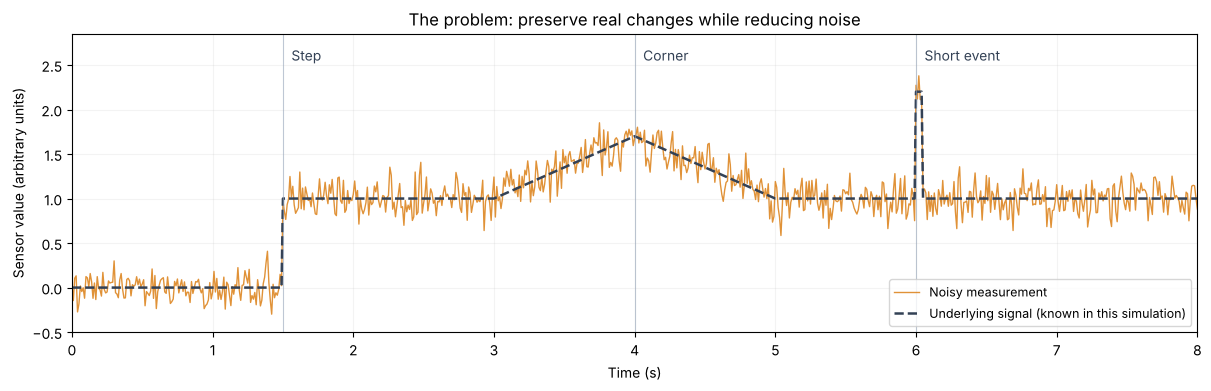

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Synthetic sensor data: the short event is real signal, not an outlier.
fs = 100  # observations per second
time_s = np.arange(801) / fs
rng = np.random.default_rng(42)
step = (time_s >= 1.5).astype(float)
triangle = 0.7 * np.maximum(1 - np.abs(time_s - 4.0), 0)
short_event = 1.2 * ((time_s >= 6.0) & (time_s < 6.05))
true_signal = step + triangle + short_event
signal_df = pd.DataFrame({
    'Time_s': time_s,
    'Underlying_signal': true_signal,
    'Measurement': true_signal + rng.normal(0, 0.14, len(time_s)),
})

fig, ax = plt.subplots(figsize=(12, 3.8), layout='constrained')
ax.plot(time_s, signal_df['Measurement'], color='#d97706', linewidth=1,
        alpha=0.8, label='Noisy measurement')
ax.plot(time_s, true_signal, color='#334155', linestyle='--', linewidth=1.8,
        label='Underlying signal (known in this simulation)')
for x, label in [(1.5, 'Step'), (4.0, 'Corner'), (6.0, 'Short event')]:
    ax.axvline(x, color='#94a3b8', linewidth=0.8, alpha=0.6)
    ax.text(x + 0.06, 2.55, label, fontsize=10, color='#334155')
ax.set(title='The problem: preserve real changes while reducing noise',
       xlabel='Time (s)', ylabel='Sensor value (arbitrary units)',
       xlim=(0, 8), ylim=(-0.5, 2.85))
ax.grid(alpha=0.15)
ax.legend(loc='lower right', fontsize=9)
plt.show()


### 2. The idea: average nearby measurements
A **simple moving average** replaces each value with the average of a group of nearby values. This group is the **window**. Every value inside it has the same weight.

For a window of 3, using the current and previous measurements:

| Measurements in the window | Calculation | Smoothed value |
|---|---|---:|
| **10, 12, 11**, 15, 13 | (10 + 12 + 11) / 3 | 11.00 |
| 10, **12, 11, 15**, 13 | (12 + 11 + 15) / 3 | 12.67 |
| 10, 12, **11, 15, 13** | (11 + 15 + 13) / 3 | 13.00 |

The window moves one observation forward each time. A single high or low measurement has less influence because it is averaged with its neighbours.

In pandas, `rolling(window=3)` creates the windows and `.mean()` calculates their averages. The original values remain in a separate column.


### 3. How much should we smooth? Compare three window sizes
We apply the same method to the **same noisy signal**, changing only the window size.

| Window size | Approximate duration at 100 observations/s | What to look for |
|---|---|---|
| 3 observations | 0.03 s | Fast response, but much of the noise remains |
| 11 observations | 0.11 s | Less noise, with some loss of sharp detail |
| 31 observations | 0.31 s | Strong smoothing, but more distortion of short events |

These are **trailing windows**: each average uses the current measurement and the previous `window - 1` measurements. This can be computed as new measurements arrive.

First compare the full signals. Then inspect the three close-ups: **step response, corner shape, and short-event height**.


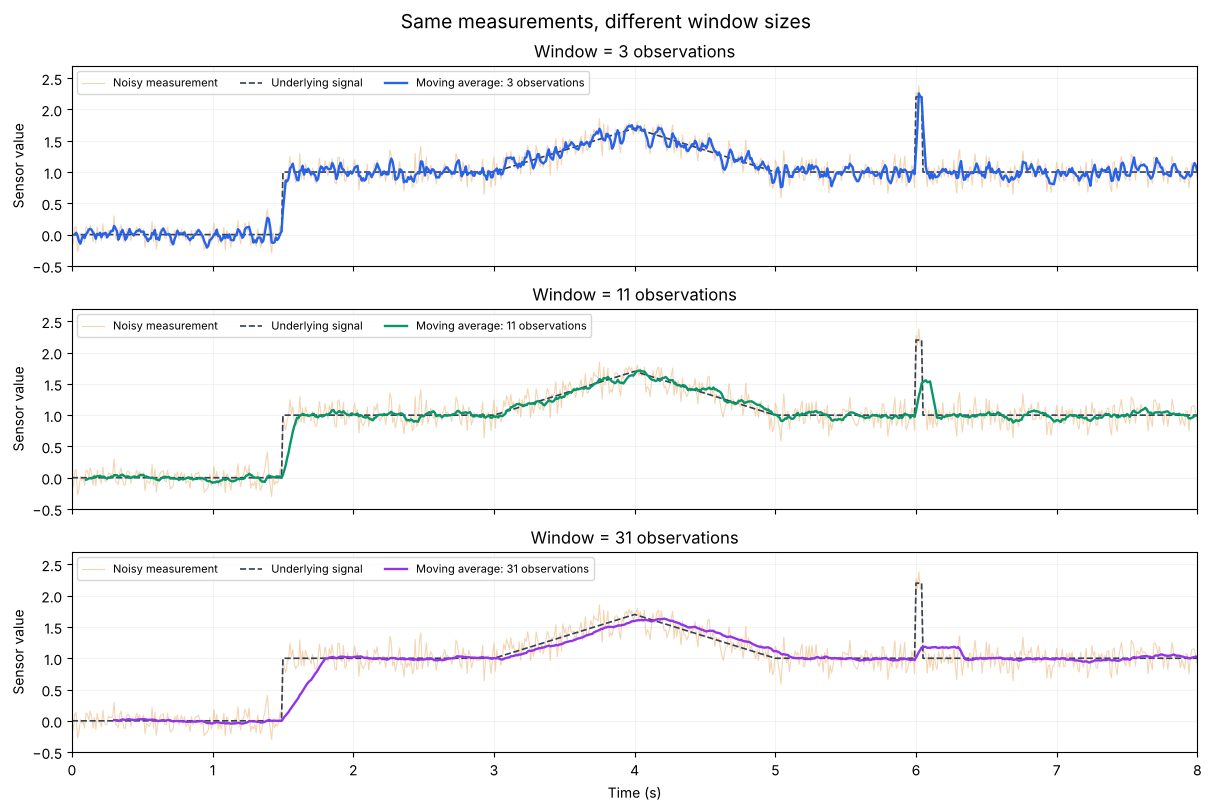

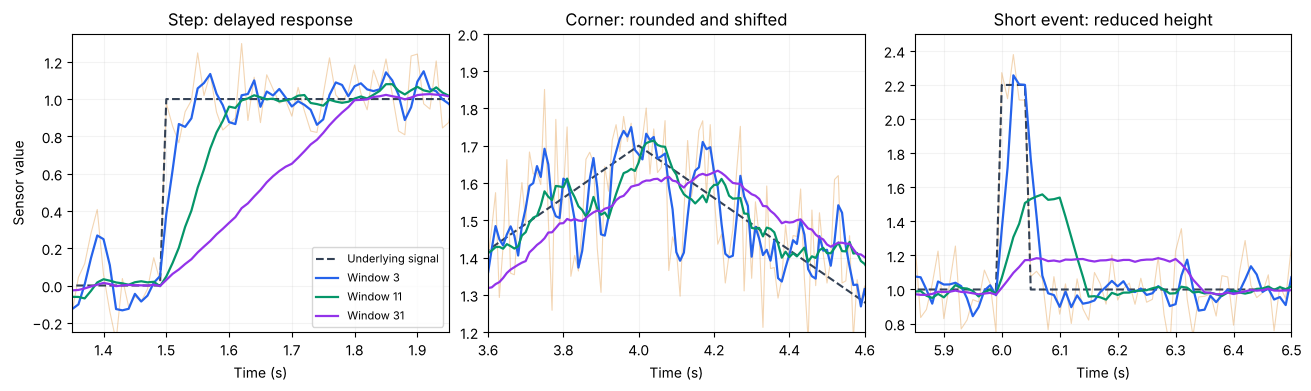

In [5]:
windows = (3, 11, 31)
colors = {3: '#2563eb', 11: '#059669', 31: '#9333ea'}
for window in windows:
    signal_df[f'MA_{window}'] = (
        signal_df['Measurement']
        .rolling(window=window, min_periods=window, center=False)
        .mean()
    )

# One panel per window keeps the comparison readable.
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                         sharey=True, layout='constrained')
for ax, window in zip(axes, windows):
    ax.plot(time_s, signal_df['Measurement'], color='#d97706',
            linewidth=0.8, alpha=0.3, label='Noisy measurement')
    ax.plot(time_s, true_signal, color='#334155', linestyle='--',
            linewidth=1.2, label='Underlying signal')
    ax.plot(time_s, signal_df[f'MA_{window}'], color=colors[window],
            linewidth=1.7, label=f'Moving average: {window} observations')
    ax.set(title=f'Window = {window} observations', ylabel='Sensor value',
           xlim=(0, 8), ylim=(-0.5, 2.7))
    ax.grid(alpha=0.15)
    ax.legend(loc='upper left', fontsize=8, ncol=3)
axes[-1].set_xlabel('Time (s)')
fig.suptitle('Same measurements, different window sizes', fontsize=14)
plt.show()

# Close-ups show the information that smoothing can remove or delay.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
regions = [
    ('Step: delayed response', (1.35, 1.95), (-0.25, 1.35)),
    ('Corner: rounded and shifted', (3.6, 4.6), (1.2, 2.0)),
    ('Short event: reduced height', (5.85, 6.5), (0.75, 2.5)),
]
for ax, (title, limits, value_limits) in zip(axes, regions):
    ax.plot(time_s, signal_df['Measurement'], color='#d97706',
            linewidth=0.8, alpha=0.3)
    ax.plot(time_s, true_signal, color='#334155', linestyle='--',
            linewidth=1.5, label='Underlying signal')
    for window in windows:
        ax.plot(time_s, signal_df[f'MA_{window}'], color=colors[window],
                linewidth=1.6, label=f'Window {window}')
    ax.set(title=title, xlim=limits, ylim=value_limits, xlabel='Time (s)')
    ax.grid(alpha=0.15)
axes[0].set_ylabel('Sensor value')
axes[0].legend(fontsize=8, loc='lower right')
plt.show()


<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *the formula was broken (LaTeX backslashes missing); one sentence on leakage added*

### 4. What do we learn?
- **Noise:** Larger windows reduce random fluctuations more strongly in this example.
- **Corners:** Sharp changes are rounded, so the shape is less accurately preserved.
- **Short events:** The brief pulse is a real event. A large window mixes it with many baseline values, reducing its height and spreading it over time.
- **Delay:** After the step, a trailing window still contains older, lower values. The average begins responding immediately, but takes longer to reach the new level when the window is larger.

**A smoother curve is not automatically a better representation of the data.**

### How should we choose the window size?
Start with the shortest real event you need to preserve and the sampling frequency. Our short event lasts **0.05 seconds**. A 31-observation window covers approximately **0.31 seconds**, so it strongly dilutes this event.

Compare several sizes and check both noise reduction and the preservation of meaningful changes. There is no universal best window. In an ML workflow, choose preprocessing settings using training/validation data, not the final test set.

### Practical limitations
- Sort observations by time. A window of 11 means **11 observations**, not automatically 11 seconds. The duration comparison above assumes regularly sampled data.
- `min_periods=window` leaves the first `window - 1` results as `NaN` because the full window is not yet available.
- A **centered** window uses neighbours on both sides. It does not have the same systematic lag as this trailing average, but still blurs details and needs future observations. It is suitable for retrospective analysis; it cannot produce the current result immediately in a live stream. <span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> Used as a *feature* for forecasting, a centered window is **look-ahead leakage**: the value at time $t$ contains $x_{t+1},\dots,x_{t+(w-1)/2}$ (see the small demo below).
- When predicting the current measurement, exclude that measurement from the feature, for example with `shift(1)` before `rolling(...)`.
- Moving averages are sensitive to extreme values. Smoothing is not a replacement for outlier detection, and real short events should not automatically be treated as noise.

**Connection to data cleaning:** Smoothing prepares noisy measurements for analysis or machine learning while trying to preserve relevant information.

**Takeaway for the presentation:** "A larger window reduces noise more strongly, but can blur sharp changes and hide short events. A trailing moving average also introduces delay."

<details>
<summary>Optional: the formula behind the example</summary>

$$MA_t = \frac{1}{w}\sum_{j=0}^{w-1}x_{t-j}$$

Add the current and previous $w-1$ measurements, then divide by $w$.

</details>

**Reference:** [pandas: rolling](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html). All data, code, and figures in this section are synthetic examples created for this notebook.


In [6]:
# [ADDED]
# Trailing vs. centered window on a tiny step signal (step at t = 4)
s = pd.Series([0, 0, 0, 0, 1, 1, 1, 1], dtype=float)
demo = pd.DataFrame({
    "x": s,
    "trailing_3": s.rolling(3).mean(),               # uses x_t, x_{t-1}, x_{t-2}  -> causal, lags
    "centered_3": s.rolling(3, center=True).mean(),  # uses x_{t+1} -> 'sees' the step at t = 3 (look-ahead!)
    "trailing_3_shift1": s.shift(1).rolling(3).mean(),  # excludes x_t -> safe feature to predict x_t
})
demo.round(2)

,x,trailing_3,centered_3,trailing_3_shift1
0,0.0,NaN,NaN,NaN
1,0.0,NaN,0.00,NaN
2,0.0,0.00,0.00,NaN
3,0.0,0.00,0.33,0.00
4,1.0,0.33,0.67,0.00
5,1.0,0.67,1.00,0.33
6,1.0,1.00,1.00,0.67
7,1.0,1.00,NaN,1.00


## (iii) Binning and discretization



<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Binning (discretization)** maps a continuous feature $x$ to one of $k$ intervals $(b_{j-1}, b_j]$ given by bin edges $b_0 < b_1 < \dots < b_k$.

| Strategy | Edges | pandas / sklearn | Property |
|---|---|---|---|
| Equal width | $b_j = x_{\min} + j\,\frac{x_{\max}-x_{\min}}{k}$ | `pd.cut(x, k)`, `strategy="uniform"` | sensitive to outliers (almost empty bins) |
| Equal frequency | empirical quantiles $q_{j/k}$ | `pd.qcut(x, k)`, `strategy="quantile"` | ≈ same number of samples per bin |
| Domain knowledge | fixed thresholds (e.g. age groups, frost < 0 °C) | `pd.cut(x, bins=[...])` | interpretable |
| Clustering | 1-D k-means centres | `strategy="kmeans"` | adapts to clusters |

**Why bin?** It reduces the effect of small measurement noise and outliers (classical *smoothing by bin means*), and one-hot encoded bins let a **linear** model learn a non-linear, step-shaped effect. **Cost:** information inside a bin is lost, and results depend on the edges. Tree-based models find their own split points and rarely benefit.

**Leakage:** data-dependent edges (quantiles, min/max) are statistics of the data, so compute them on the **training set** and reuse them for validation/test. `KBinsDiscretizer` does this with `fit`/`transform`; test values outside the training range fall into the first/last bin.

In [7]:
# [ADDED]
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer

temp = data_df["temperature"].dropna()             # temperatures from section (i)
t_train, t_test = train_test_split(temp, test_size=0.3, random_state=0)

# Domain-defined bins (fixed edges -> no fitting, no leakage); intervals are right-closed (a, b]
cats = pd.cut(t_train, bins=[-np.inf, 18, 22, np.inf], labels=["cool", "normal", "warm"])
print("Fixed edges, counts:", cats.value_counts().sort_index().to_dict())

# Equal-width vs. equal-frequency: edges learned on the TRAINING set only
for strategy in ["uniform", "quantile"]:
    kbd = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy=strategy)
    kbd.fit(t_train.to_frame())
    test_bins = kbd.transform(t_test.to_frame()).ravel().astype(int)
    print(f"{strategy:8s} edges: {np.round(kbd.bin_edges_[0], 1)} | test counts per bin: {np.bincount(test_bins, minlength=4)}")

Fixed edges, counts: {'cool': 14, 'normal': 30, 'warm': 19}
uniform  edges: [13.  16.3 19.5 22.8 26. ] | test counts per bin: [ 2 10 12  3]
quantile edges: [13.  18.  20.  22.8 26. ] | test counts per bin: [ 6  6 12  3]


## (iv) Missing value imputation: forward/backward fill and median imputation



<span style="background-color:#ffe5b4;color:#8a4b00;padding:2px 8px;border-radius:4px;font-weight:bold">[CORRECTED]</span> *garbled median example fixed (imputed lists were broken); KDE removed from the list of imputation methods (KDE is density estimation/spatial smoothing, not an imputer); remaining 'advanced techniques' moved to the end*

Imputation replaces missing values (`NaN`) with estimates. The right method depends on the feature’s meaning and whether observations have a meaningful order.

---

#### 1. Forward Fill (`ffill`)

Replaces missing values with the last observed value: past → future.

Example: A device’s operating mode remains unchanged until a new mode is recorded.

| Time | Recorded mode | Forward-filled |
|------|---------------|----------------|
| 09:00 | Idle | Idle |
| 09:01 | NaN | Idle |
| 09:02 | Running | Running |
| 09:03 | NaN | Running |

```python
df["mode"] = df["mode"].ffill()
```

- Useful for persistent states or short gaps in slowly changing measurements.
- Can propagate stale values across long gaps.
- Leading missing values remain missing.
- Consider a gap limit to avoid filling long stretches.
- For forward/backward fill needs data preparation e.g. sort by time and fill separately for each entity/sensor/customer etc.

---

#### 2. Backward Fill (`bfill`)

Replaces missing values with the next observed value: future → past.

Example: A reporting system records each interval’s status at its end. Backward fill assigns that status to earlier rows within the interval—only if this matches the logging convention.

| Time | Recorded interval status | Backward-filled |
|------|--------------------------|-----------------|
| 09:01 | NaN | Normal |
| 09:02 | Normal | Normal |
| 09:03 | NaN | Warning |
| 09:04 | Warning | Warning |
| 09:05 | NaN | NaN |

```python
df["interval_status"] = df["interval_status"].bfill()
```

- Useful for retrospective processing when later values validly describe earlier gaps.
- Can cause look-ahead leakage in forecasting or real-time prediction.
- Trailing missing values remain missing.
- Consider a gap limit to avoid filling long stretches.
- For forward/backward fill needs data preparation e.g. sort by time and fill separately for each entity/sensor/customer etc.

---

#### 3. Median Imputation

Replaces missing numerical values with the feature’s training-set median.

Example: Missing apartment sizes are replaced with the median observed training size. An unusually large apartment has limited influence on the estimate.

**Avoid data leakage:** Learn imputation statistics only from training data, and reuse them for validation/test data. For time-dependent predictions, use only information available at prediction time.

```text
Training values: [40, 50, NaN, 60, 70, 300]
Median:          60          (mean would be 104!)
Imputed values:  [40, 50, 60, 60, 70, 300]

Test values:     [NaN, 80]
Imputed values:  [60, 80]    ← reuse the training median
```

```python
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)
```
- Useful as a simple baseline for numerical tabular features.
- Less sensitive to outliers than mean imputation.
- Creates a concentration at the median and can distort variance and feature relationships.

---

#### Other options (not required here)

* Most-frequent imputation (`SimpleImputer(strategy="most_frequent")`) for categorical features.
* KNN imputation (`KNNImputer`): use the values of the *k* most similar rows.
* `add_indicator=True` adds a binary *was-missing* column so the model can still use the missingness pattern.


In [8]:
# [ADDED]
# (a) ffill / bfill on a log with two sensors: sort by time and fill PER SENSOR
log = pd.DataFrame({
    "sensor": ["A", "B"] * 4,
    "time":   np.repeat(np.arange(4), 2),
    "value":  [1.0, np.nan, np.nan, 5.0, np.nan, np.nan, 4.0, 7.0],
}).sort_values(["sensor", "time"])
log["ffill_naive"] = log["value"].ffill()                      # WRONG: A's last value leaks into sensor B
log["ffill_group"] = log.groupby("sensor")["value"].ffill(limit=1)  # past -> future, at most 1 step
log["bfill_group"] = log.groupby("sensor")["value"].bfill()   # future -> past: look-ahead in forecasting!
display(log)

# (b) Median imputation with statistics learned on the training set only (data from section i)
from sklearn.impute import SimpleImputer
X_train, X_test = train_test_split(data_df, test_size=0.3, random_state=0)
imputer = SimpleImputer(strategy="median", add_indicator=True).fit(X_train)
print("Training medians :", np.round(imputer.statistics_, 2))
print("Full-data medians:", np.round(data_df.median().values, 2), "<- would leak test information")
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=imputer.get_feature_names_out(), index=X_test.index)
print("NaN left in test :", int(X_test_imp.isna().sum().sum()))
display(X_test_imp[X_test.isna().any(axis=1)].head(3).round(2))

,sensor,time,value,ffill_naive,ffill_group,bfill_group
0,A,0,1.0,1.0,1.0,1.0
2,A,1,NaN,1.0,1.0,4.0
4,A,2,NaN,1.0,NaN,4.0
6,A,3,4.0,4.0,4.0,4.0
1,B,0,NaN,4.0,NaN,5.0
3,B,1,5.0,5.0,5.0,5.0
5,B,2,NaN,5.0,5.0,7.0
7,B,3,7.0,7.0,7.0,7.0


Training medians : [20.28 47.2 ]
Full-data medians: [20.14 50.99] <- would leak test information
NaN left in test : 0


,temperature,humidity,missingindicator_temperature,missingindicator_humidity
26,17.77,47.20,0.0,1.0
55,20.28,35.07,1.0,0.0
53,20.28,58.11,1.0,0.0


## (v) Outlier detection and removal



<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

An **outlier** is an observation far away from the bulk of the data. It can be an **error** (sensor fault, typo, wrong unit) → correct or remove it, or a **genuine rare value** → keep it (use robust methods, transform, or clip/winsorize instead). Always check the domain before deleting.

| Rule | Definition | Outlier if | Comment |
|---|---|---|---|
| IQR (Tukey) | $\mathrm{IQR}=Q_3-Q_1$ | $x<Q_1-1.5\,\mathrm{IQR}$ or $x>Q_3+1.5\,\mathrm{IQR}$ | robust, no distribution assumed |
| z-score | $z=\dfrac{x-\bar x}{s}$ | $\lvert z\rvert>3$ | assumes ≈ normal data; $\bar x$ and $s$ are themselves inflated by outliers (**masking**) |
| robust z-score | $z_r=0.6745\,\dfrac{x-\tilde x}{\mathrm{MAD}}$, $\mathrm{MAD}=\mathrm{median}\lvert x-\tilde x\rvert$ | $\lvert z_r\rvert>3.5$ | median/MAD are robust |

All three rules are **univariate**. In an ML pipeline, learn the thresholds on the **training set**; never drop test rows (in production you cannot discard an incoming sample, you need a rule for it). The example below uses compression tests of concrete cores (synthetic data with three injected outliers).

Concrete Core Samples with Structural Locations (first 10 rows):


,Sample_ID,Block,Storey,Compression_Strength_MPa
0,Core_01,Block A,Storey 1,43.403018
1,Core_02,Block A,Storey 1,33.967111
2,Core_03,Block A,Storey 1,45.738314
3,Core_04,Block A,Storey 2,42.337578
4,Core_05,Block A,Storey 2,78.200000
5,Core_06,Block A,Storey 2,38.840581
6,Core_07,Block A,Storey 2,37.249519
7,Core_08,Block A,Storey 3,38.404548
8,Core_09,Block A,Storey 3,40.666237
9,Core_10,Block A,Storey 3,38.424631



Sample counts per Block and Storey:


,Block,Storey,Sample_Count
0,Block A,Storey 1,3
1,Block A,Storey 2,4
2,Block A,Storey 3,3
3,Block B,Storey 1,3
4,Block B,Storey 2,3
5,Block B,Storey 3,4
6,Block C,Storey 1,3
7,Block C,Storey 2,3
8,Block C,Storey 3,6



IQR Outlier Thresholds: Lower Bound = 32.26 MPa, Upper Bound = 46.46 MPa
Detected Outliers:


,Sample_ID,Block,Storey,Compression_Strength_MPa
4,Core_05,Block A,Storey 2,78.2
26,Core_27,Block C,Storey 3,15.0
31,Core_32,Block C,Storey 3,12.5


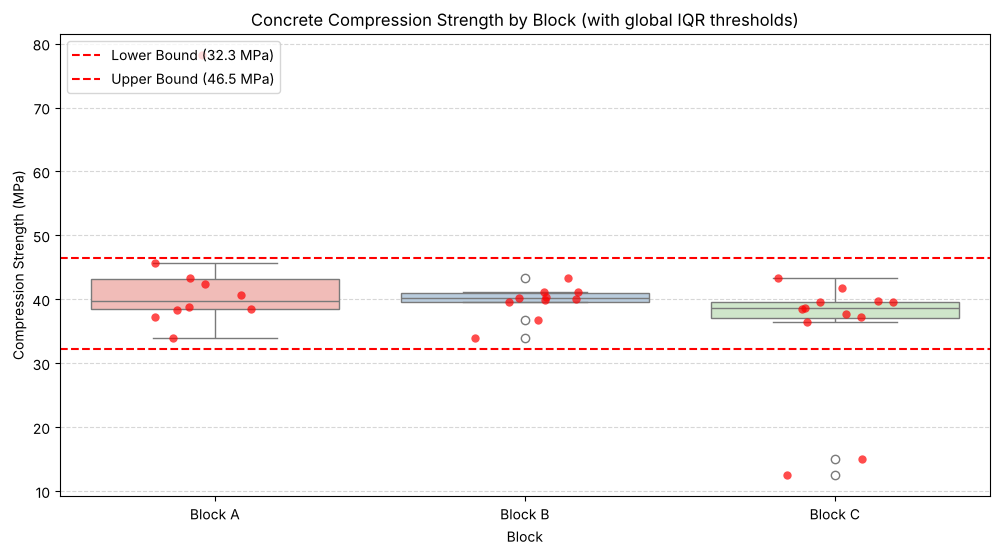

In [9]:
# 1. Generate structured concrete core data with Block and Storey information
# We will distribute 32 samples across Blocks and Storeys ensuring at least 3 samples per storey.
# Normally we have this data from compression tests :))
np.random.seed(42)

# Create structural metadata
blocks = ['Block A', 'Block B', 'Block C']
storeys = ['Storey 1', 'Storey 2', 'Storey 3']

records = []
sample_counter = 1

# Populate with at least 3 samples per storey per block
for block in blocks:
    for storey in storeys:
        # Generate 3 to 4 samples per storey
        num_samples_in_storey = np.random.choice([3, 4])
        for _ in range(num_samples_in_storey):
            if sample_counter <= 32:
                records.append({
                    'Sample_ID': f"Core_{sample_counter:02d}",
                    'Block': block,
                    'Storey': storey
                })
                sample_counter += 1

# If we still need to reach exactly 32 samples
while len(records) < 32:
    records.append({
        'Sample_ID': f"Core_{len(records)+1:02d}",
        'Block': 'Block C',
        'Storey': 'Storey 3'
    })

df_concrete = pd.DataFrame(records)

# Generate strength values with outliers
normal_strengths = np.random.normal(loc=40.0, scale=3.0, size=29)
outliers = np.array([12.5, 78.2, 15.0])
compression_strengths = np.concatenate([normal_strengths, outliers])
np.random.shuffle(compression_strengths)

df_concrete['Compression_Strength_MPa'] = compression_strengths

print("Concrete Core Samples with Structural Locations (first 10 rows):")
display(df_concrete.head(10))

# Verify minimum sample constraint per storey
print("\nSample counts per Block and Storey:")
display(df_concrete.groupby(['Block', 'Storey']).size().reset_index(name='Sample_Count'))

# 2. Outlier Detection using the Interquartile Range (IQR) method
Q1 = df_concrete['Compression_Strength_MPa'].quantile(0.25)
Q3 = df_concrete['Compression_Strength_MPa'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_detected = df_concrete[
    (df_concrete['Compression_Strength_MPa'] < lower_bound) |
    (df_concrete['Compression_Strength_MPa'] > upper_bound)
]

print(f"\nIQR Outlier Thresholds: Lower Bound = {lower_bound:.2f} MPa, Upper Bound = {upper_bound:.2f} MPa")
print("Detected Outliers:")
display(outliers_detected)

# 3. Outlier Removal
df_cleaned = df_concrete[
    (df_concrete['Compression_Strength_MPa'] >= lower_bound) &
    (df_concrete['Compression_Strength_MPa'] <= upper_bound)
]

# 4. Visualization: Boxplot grouped by Block with points overlaid
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_concrete, x='Block', y='Compression_Strength_MPa', palette='Pastel1', hue='Block', legend=False)
sns.stripplot(data=df_concrete, x='Block', y='Compression_Strength_MPa', color='red', size=6, jitter=0.2, alpha=0.7)
plt.axhline(lower_bound, color='red', linestyle='--', label=f'Lower Bound ({lower_bound:.1f} MPa)')
plt.axhline(upper_bound, color='red', linestyle='--', label=f'Upper Bound ({upper_bound:.1f} MPa)')
plt.title('Concrete Compression Strength by Block (with global IQR thresholds)')
plt.ylabel('Compression Strength (MPa)')
plt.legend(loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [10]:
# [ADDED]
# z-score vs. robust z-score on the same concrete data
x = df_concrete["Compression_Strength_MPa"]
z = (x - x.mean()) / x.std()
mad = (x - x.median()).abs().median()
z_robust = 0.6745 * (x - x.median()) / mad
print(f"mean = {x.mean():.1f} MPa, std = {x.std():.1f} MPa  (inflated by the outliers; clean std is about 3 MPa)")
print("Outliers |z| > 3      :", sorted(x[z.abs() > 3].round(1).tolist()))
print("Outliers |z_r| > 3.5  :", sorted(x[z_robust.abs() > 3.5].round(1).tolist()))
print("Outliers IQR rule     :", sorted(outliers_detected["Compression_Strength_MPa"].round(1).tolist()))

mean = 39.2 MPa, std = 9.9 MPa  (inflated by the outliers; clean std is about 3 MPa)
Outliers |z| > 3      : [78.2]
Outliers |z_r| > 3.5  : [12.5, 15.0, 78.2]
Outliers IQR rule     : [12.5, 15.0, 78.2]


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span>

**Interpretation:** the classical z-score finds only the 78.2 MPa core; the two low values (12.5 and 15.0 MPa) are *masked* because the outliers inflate the standard deviation from ≈ 3 to ≈ 10 MPa. The IQR rule and the robust z-score find all three. Note on the boxplot above: the whiskers are computed per block, the dashed lines are the *global* IQR fences.

<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *explanation of how=, keys, validate=, duplicates and indicator added; typos fixed*

## (vi) Data integration: merging pandas DataFrames

Often you need to merge different data sources. There you have to deal with different units of measurement, duplicates and different time resolutions (daily vs. weekly) etc.

`left.merge(right, on=key, how=...)` combines rows whose **key** values match (like a SQL join):

| `how=` | Keeps | Non-matching rows |
|---|---|---|
| `"inner"` (default) | keys present in **both** tables | dropped |
| `"left"` | all keys of the left table | right columns become `NaN` |
| `"right"` | all keys of the right table | left columns become `NaN` |
| `"outer"` | union of all keys | `NaN` on the missing side |

**Pitfalls:** (1) Duplicate keys multiply rows: a key that occurs $m$ times left and $n$ times right yields $m\cdot n$ rows. Check the expected relation with `validate="one_to_one"`, `"one_to_many"` or `"many_to_one"` (raises `MergeError` otherwise). (2) Keys must have the same dtype and format (`1` vs `"1"`, trailing spaces, upper/lower case). (3) Unmatched rows silently create `NaN`s; `indicator=True` adds a `_merge` column (`both`, `left_only`, `right_only`) to inspect them. (4) Aggregated features (e.g. mean order value per customer) must be computed from training data / past data only; for time series use `pd.merge_asof(..., direction="backward")` to attach only the latest *past* record.

Example: one customer can have many orders (one-to-many).

```python
import pandas as pd

customers = pd.DataFrame({
    "customer_id": [1, 2, 3],
    "name": ["Alice", "Bob", "Charlie"],
})

orders = pd.DataFrame({
    "customer_id": [1, 1, 2],
    "product": ["Laptop", "Mouse", "Keyboard"],
})

# Keep every customer and attach matching orders.
merged = customers.merge(orders, on="customer_id", how="left")
```

```
   customer_id     name   product
0            1    Alice    Laptop
1            1    Alice     Mouse
2            2      Bob  Keyboard
3            3  Charlie       NaN
```

In [11]:
# [ADDED]
from pandas.errors import MergeError
customers = pd.DataFrame({"customer_id": [1, 2, 3], "name": ["Alice", "Bob", "Charlie"]})
orders = pd.DataFrame({"customer_id": [1, 1, 2, 4], "product": ["Laptop", "Mouse", "Keyboard", "Monitor"]})

for how in ["inner", "left", "right", "outer"]:
    m = customers.merge(orders, on="customer_id", how=how, indicator=True, validate="one_to_many")
    print(f"{how:5s}: {len(m)} rows, _merge = {m['_merge'].value_counts().to_dict()}")

# A duplicated key in 'customers' (data-entry error) silently multiplies rows ...
customers_dup = pd.concat([customers, customers.iloc[[0]]], ignore_index=True)
print("rows with duplicated key:", len(customers_dup.merge(orders, on="customer_id")), "instead of 3")
# ... validate= detects it
try:
    customers_dup.merge(orders, on="customer_id", validate="one_to_many")
except MergeError as e:
    print("MergeError:", str(e).splitlines()[0])

inner: 3 rows, _merge = {'both': 3, 'left_only': 0, 'right_only': 0}
left : 4 rows, _merge = {'both': 3, 'left_only': 1, 'right_only': 0}
right: 4 rows, _merge = {'both': 3, 'right_only': 1, 'left_only': 0}
outer: 5 rows, _merge = {'both': 3, 'left_only': 1, 'right_only': 1}
rows with duplicated key: 5 instead of 3
MergeError: Merge keys are not unique in left dataset; not a one-to-many merge


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *takeaways were empty*

## Takeaways

- **What should every ML practitioner remember?**
  - `np.nan != np.nan`: test missing values with `isna()`; NaN turns integer columns into `float64`; sentinels like `-999` must be converted to NaN first.
  - Every *data-dependent* cleaning step (imputation medians, bin edges, outlier thresholds, aggregated merge features) is a fitted transformation: **fit on the training set, apply to validation/test** (e.g. inside a `Pipeline`).
  - Moving averages trade noise reduction against delay and loss of sharp/short events; the window size is a hyperparameter.
  - Use the median and IQR / MAD rather than mean and standard deviation when the data may contain outliers.
  - After a merge, check the number of rows, the `_merge` indicator and the new NaNs.
- **What are common pitfalls?**
  - Look-ahead leakage in time series: `bfill`, centered rolling windows, or a rolling mean that includes the current target value (use `shift(1)`).
  - `ffill`/`bfill` without sorting by time or without `groupby(entity)` → values leak across sensors/customers; unlimited fills propagate stale values over long gaps.
  - Imputing or computing statistics on the full dataset before the train/test split.
  - z-score masking (outliers inflate $s$); deleting genuine rare events as "outliers"; dropping test samples.
  - Duplicate or mismatched keys in `merge` silently multiply or drop rows.
- **When does this technique really matter?**
  - Real sensor/IoT time series (gaps, noise, spikes), medical and survey data (many NaNs, often not missing at random), and any project that joins several tables or databases.
  - With models that cannot handle NaN or are sensitive to outliers (linear models, k-NN, SVM, neural nets).
  - Whenever the model is evaluated on a time-ordered or held-out set: careless cleaning makes validation scores optimistic.


<span style="background-color:#d4edda;color:#155724;padding:2px 8px;border-radius:4px;font-weight:bold">[ADDED]</span> *references were empty*

## References

1. pandas – Working with missing data: https://pandas.pydata.org/docs/user_guide/missing_data.html
2. pandas – `DataFrame.rolling`: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rolling.html
3. pandas – `cut` / `qcut`: https://pandas.pydata.org/docs/reference/api/pandas.cut.html, https://pandas.pydata.org/docs/reference/api/pandas.qcut.html
4. pandas – `ffill` / `bfill`: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.ffill.html
5. pandas – Merge, join, concatenate: https://pandas.pydata.org/docs/user_guide/merging.html
6. scikit-learn – Imputation of missing values: https://scikit-learn.org/stable/modules/impute.html
7. scikit-learn – `KBinsDiscretizer`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html
8. B. Iglewicz, D. Hoaglin (1993): *How to Detect and Handle Outliers* (robust z-score / MAD). NIST e-Handbook: https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
9. J. W. Tukey (1977): *Exploratory Data Analysis* (IQR fences / boxplot).

All data, code and figures in this notebook are synthetic examples created for this notebook.
